# Luna – Menstrual Cycle Tracker and Wellness App

## Introduction

Luna is a Python-based menstrual cycle tracking and wellness application. It records period dates and daily wellness information, estimates a possible upcoming period from previous cycle lengths, and presents summaries and charts. The Streamlit application provides the interactive user interface; this notebook demonstrates the Python calculations, data analysis, visualisation, and SQLite concepts behind the project.

## Objectives

- Calculate cycle lengths and period durations from dates.
- Use Pandas and NumPy to summarise cycle and wellness data.
- Visualise cycle lengths, mood frequency, symptoms, and energy levels using Matplotlib.
- Demonstrate SQL table creation, insertion, retrieval, and filtering with SQLite.
- Estimate a possible next period date from recorded sample cycles.
- Inspect the schema of the app's `luna.db` database in read-only mode when it is available.

## Important note about the data

Most analysis cells use clearly labelled sample records so the notebook can run even when the app database is not present. These example values are for demonstrating code only and are not medical advice. Menstrual cycles can vary, and an estimated date is not a medical prediction.

## Libraries used

- **Pandas:** tables and data manipulation.
- **NumPy:** numerical statistics.
- **Matplotlib:** charts.
- **SQLite (`sqlite3`):** relational data storage and SQL queries.
- **Datetime utilities:** date calculations.

In [1]:

import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import date, timedelta

**1. Sample Period Data**

The following sample data represents period start and end dates. Sample records allow us to test calculations without using personal information.


In [2]:

periods = pd.DataFrame({
    "Start Date": pd.to_datetime([
        "2026-06-01",
        "2026-06-29",
        "2026-07-27",
        "2026-08-25"
    ]),
    "End Date": pd.to_datetime([
        "2026-06-05",
        "2026-07-03",
        "2026-07-31",
        "2026-08-29"
    ])
})

periods

,Start Date,End Date
0,2026-06-01,2026-06-05
1,2026-06-29,2026-07-03
2,2026-07-27,2026-07-31
3,2026-08-25,2026-08-29


**2. Cycle Length and Period Duration**

Cycle length is the number of days between the start of one period and the start of the next period.

Period duration is the number of calendar days from the period start date to its end date, including both dates.


In [3]:

periods = periods.sort_values("Start Date").reset_index(drop=True)

periods["Cycle Length"] = periods["Start Date"].diff().dt.days

periods["Period Duration"] = (
    periods["End Date"] - periods["Start Date"]
).dt.days + 1

periods


,Start Date,End Date,Cycle Length,Period Duration
0,2026-06-01,2026-06-05,NaN,5
1,2026-06-29,2026-07-03,28.0,5
2,2026-07-27,2026-07-31,28.0,5
3,2026-08-25,2026-08-29,29.0,5


**3. Statistical Analysis Using NumPy**

NumPy provides functions for calculating the mean, minimum, maximum, and standard deviation. These statistics help summarise the recorded cycle lengths.


In [4]:

cycle_lengths = periods["Cycle Length"].dropna().to_numpy()

if len(cycle_lengths) > 0:
    print("Average cycle length:", round(np.mean(cycle_lengths), 2), "days")
    print("Shortest recorded cycle:", np.min(cycle_lengths), "days")
    print("Longest recorded cycle:", np.max(cycle_lengths), "days")
    print("Standard deviation:", round(np.std(cycle_lengths), 2), "days")
else:
    print("At least two period start dates are needed.")


Average cycle length: 28.33 days
Shortest recorded cycle: 28.0 days
Longest recorded cycle: 29.0 days
Standard deviation: 0.47 days


**4. Visualisation of Cycle Lengths**

A line chart helps us observe how recorded cycle lengths change over time. The first record is excluded because its cycle length is unknown.


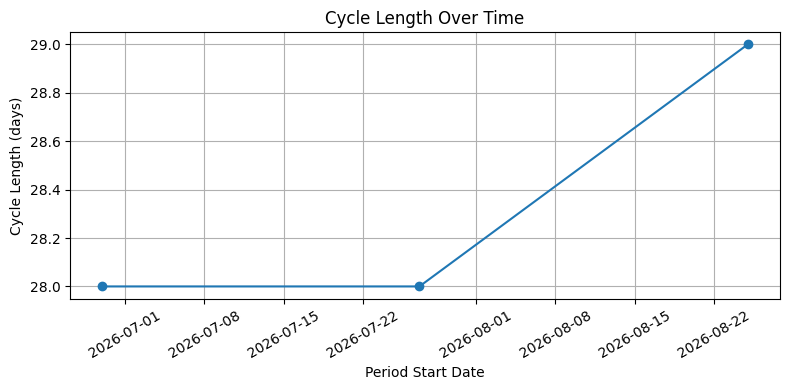

In [5]:

valid_periods = periods.dropna(subset=["Cycle Length"])

plt.figure(figsize=(8, 4))
plt.plot(
    valid_periods["Start Date"],
    valid_periods["Cycle Length"],
    marker="o"
)

plt.title("Cycle Length Over Time")
plt.xlabel("Period Start Date")
plt.ylabel("Cycle Length (days)")
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()


**Interpretation**

The sample data shows cycle lengths of 28, 28, and 29 days. The average is 28 days, and the low standard deviation indicates little variation among these sample values. These results describe only the example data and cannot predict an individual's cycle with certainty.


**5. Daily Mood and Symptom Analysis**

This section analyses sample daily wellness records using Pandas.
Each record contains a date, mood, energy level, and symptom.
The data can help demonstrate how Luna summarises daily wellness patterns.

In [6]:
daily_logs = pd.DataFrame({
    "Date": pd.to_datetime([
        "2026-08-25",
        "2026-08-26",
        "2026-08-27",
        "2026-08-28",
        "2026-08-29",
        "2026-08-30",
        "2026-08-31"
    ]),
    "Mood": [
        "Happy", "Tired", "Calm", "Tired",
        "Happy", "Low", "Calm"
    ],
    "Energy": [4, 2, 3, 2, 4, 1, 3],
    "Symptom": [
        "Cramps", "Headache", "None", "Cramps",
        "None", "Bloating", "None"
    ]
})

daily_logs

,Date,Mood,Energy,Symptom
0,2026-08-25,Happy,4,Cramps
1,2026-08-26,Tired,2,Headache
2,2026-08-27,Calm,3,None
3,2026-08-28,Tired,2,Cramps
4,2026-08-29,Happy,4,None
5,2026-08-30,Low,1,Bloating
6,2026-08-31,Calm,3,None


**Mood Frequency**

The value_counts() function counts how many times each mood appears
in the dataset. This helps summarise the recorded mood patterns.

In [7]:
mood_counts = daily_logs["Mood"].value_counts()

print("Mood frequency:")
print(mood_counts)

Mood frequency:
Mood
Happy    2
Tired    2
Calm     2
Low      1
Name: count, dtype: int64


**Symptom Frequency**

The symptom data is analysed to find the frequency of each recorded
symptom. The value None represents a day when no symptom was recorded.

In [8]:
symptom_counts = daily_logs["Symptom"].value_counts()

print("Symptom frequency:")
print(symptom_counts)

Symptom frequency:
Symptom
None        3
Cramps      2
Headache    1
Bloating    1
Name: count, dtype: int64


**Average Energy Level**

The mean() function calculates the average recorded energy level.
Energy is rated on a scale from 1 to 5 in this sample dataset.

In [9]:
average_energy = daily_logs["Energy"].mean()

print("Average energy level:", round(average_energy, 2))

Average energy level: 2.71


**6. Visualisation of Mood Distribution**

A bar chart displays the number of times each mood appears in the
sample journal data. It makes the most frequently recorded moods
easy to identify.

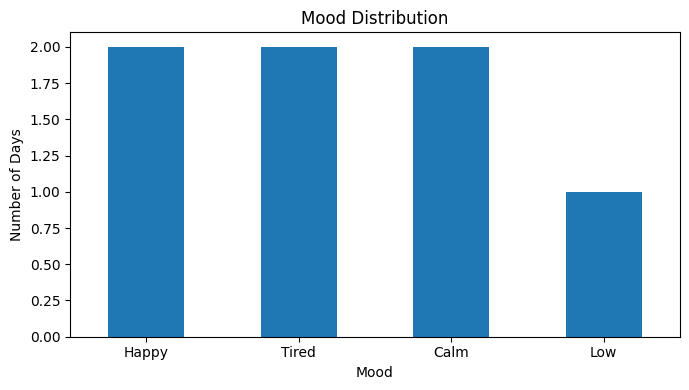

In [10]:
plt.figure(figsize=(7, 4))

mood_counts.plot(kind="bar")

plt.title("Mood Distribution")
plt.xlabel("Mood")
plt.ylabel("Number of Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Symptom Frequency Visualisation**

This bar chart compares how frequently each symptom was recorded.
The None category represents days when no symptom was recorded.

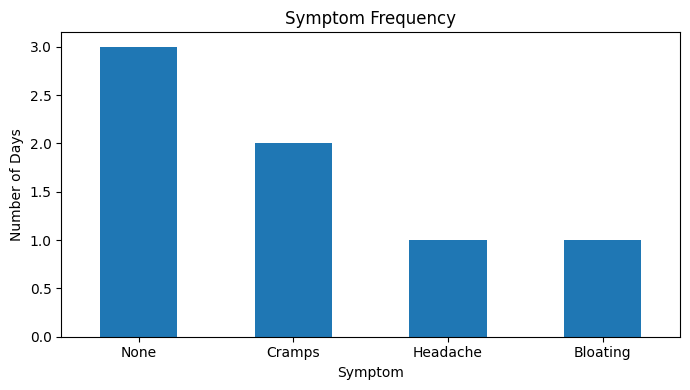

In [11]:
plt.figure(figsize=(7, 4))

symptom_counts.plot(kind="bar")

plt.title("Symptom Frequency")
plt.xlabel("Symptom")
plt.ylabel("Number of Days")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Daily Energy Level**

A line chart shows how the recorded energy level changes over time.
This helps users observe variations in their daily wellness records.

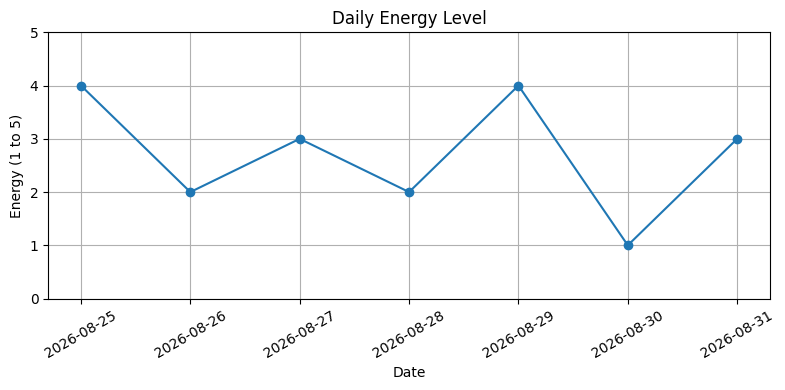

In [12]:
plt.figure(figsize=(8, 4))

plt.plot(
    daily_logs["Date"],
    daily_logs["Energy"],
    marker="o"
)

plt.title("Daily Energy Level")
plt.xlabel("Date")
plt.ylabel("Energy (1 to 5)")
plt.ylim(0, 5)
plt.xticks(rotation=30)
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretation**

The sample journal data demonstrates how Pandas can summarise moods,
symptoms, and energy levels, while Matplotlib can visualise these
patterns. The charts make the records easier to understand. However,
the sample data is used only to demonstrate the analysis and does not
establish medical relationships or conclusions.

**7. Database Operations Using SQLite**

Luna uses SQLite to store period records and daily wellness logs. This section demonstrates database operations with a separate demonstration database named `luna_notebook_demo.db`. Keeping the demonstration database separate prevents the notebook from accidentally changing the app's real data.

The SQL examples use parameterised queries (`?`) rather than joining user input directly into SQL strings.

In [13]:
# Create a persistent demonstration database in the project folder.
# This is separate from the app's luna.db file.
conn = sqlite3.connect("luna_notebook_demo.db")
cursor = conn.cursor()

cursor.execute("""
CREATE TABLE IF NOT EXISTS demo_periods (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    start_date TEXT NOT NULL,
    end_date TEXT NOT NULL
)
""")

conn.commit()
print("Demonstration database and table are ready.")

Demonstration database and table are ready.


**Insert sample records**

`INSERT OR IGNORE` is not needed here because the demo table has no unique date constraint. To keep the notebook repeatable, the next cell clears only the demonstration table before inserting its sample rows.

In [14]:
sample_periods = [
    ("2026-06-01", "2026-06-05"),
    ("2026-06-29", "2026-07-03"),
    ("2026-07-27", "2026-07-31"),
    ("2026-08-25", "2026-08-29")
]

cursor.execute("DELETE FROM demo_periods")
cursor.executemany(
    "INSERT INTO demo_periods (start_date, end_date) VALUES (?, ?)",
    sample_periods
)
conn.commit()

print("Inserted", len(sample_periods), "sample period records.")

Inserted 4 sample period records.


**Retrieve records using SQL**

`SELECT` reads rows from a table. Pandas can turn the result into a DataFrame, which is convenient for displaying and analysing records.

In [15]:
period_data = pd.read_sql_query(
    "SELECT id, start_date, end_date FROM demo_periods ORDER BY start_date",
    conn
)
period_data

,id,start_date,end_date
0,1,2026-06-01,2026-06-05
1,2,2026-06-29,2026-07-03
2,3,2026-07-27,2026-07-31
3,4,2026-08-25,2026-08-29


**Filter records using a parameterised query**

This query retrieves periods that started on or after 1 July 2026. The `?` placeholder safely passes the date as a parameter.

In [16]:
filtered_periods = pd.read_sql_query(
    """
    SELECT id, start_date, end_date
    FROM demo_periods
    WHERE start_date >= ?
    ORDER BY start_date
    """,
    conn,
    params=("2026-07-01",)
)
filtered_periods

,id,start_date,end_date
0,3,2026-07-27,2026-07-31
1,4,2026-08-25,2026-08-29


**Check the actual Luna database (read-only)**

The Streamlit app may create `luna.db` in its working directory when it runs. This cell checks whether that file is available beside the notebook and lists its tables and columns without inserting, updating, or deleting anything.

If the file is not present, the notebook continues normally. Run the notebook from the Luna project folder to give it the best chance of finding the app database. Table names and columns can differ between project versions, so this cell inspects the schema instead of assuming a fixed structure.

In [17]:
from pathlib import Path

app_db_path = Path("luna.db")

if app_db_path.exists():
    app_conn = sqlite3.connect(f"file:{app_db_path.resolve().as_posix()}?mode=ro", uri=True)
    table_info = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name",
        app_conn
    )
    print("Found Luna database:", app_db_path.resolve())
    display(table_info)

    for table_name in table_info["name"]:
        # Table names come from sqlite_master, not user input.
        safe_name = table_name.replace('"', '""')
        columns = pd.read_sql_query(f'PRAGMA table_info("{safe_name}")', app_conn)
        print(f"Columns in {table_name}:")
        display(columns[["name", "type", "notnull", "pk"]])
    app_conn.close()
else:
    print("luna.db was not found in the current folder.")
    print("The demonstration database above still shows the SQLite workflow.")

luna.db was not found in the current folder.
The demonstration database above still shows the SQLite workflow.


**Close the demonstration database**

Always close database connections when the work is complete. This releases the connection while the demonstration database file remains on disk.

In [18]:
conn.close()
print("Demonstration database connection closed.")

Demonstration database connection closed.


**8. Next Period Estimation**

Luna estimates the next period date using the average number of days
between recorded period start dates. It uses the most recent cycle
lengths to calculate an estimate. Actual menstrual cycles can vary,
so this estimate is not a medical prediction.

In [19]:
valid_lengths = periods["Cycle Length"].dropna()

if len(valid_lengths) > 0:
    avg_length = round(valid_lengths.mean())
    latest_start = periods["Start Date"].max()
    next_period = latest_start + pd.Timedelta(days=avg_length)

    print("Average cycle length:", avg_length, "days")
    print("Latest period start:", latest_start.date())
    print("Estimated next period:", next_period.date())
else:
    print("At least two period start dates are required.")

Average cycle length: 28 days
Latest period start: 2026-08-25
Estimated next period: 2026-09-22


**9. Project Findings**

The sample analysis demonstrates the following:

- Pandas can calculate cycle lengths and summarise daily wellness records.
- NumPy can calculate statistical measures such as the mean and standard deviation.
- Matplotlib can display cycle, mood, symptom, and energy trends.
- SQLite can store, retrieve, and filter period records.
- Previous period dates can be used to estimate a possible next period date.

These findings demonstrate the application's functionality using sample
data. More records would be needed to understand an individual's patterns.

**10. Conclusion**

Luna demonstrates how Python can be used to build a menstrual cycle
tracking and wellness application. It combines SQLite for data storage,
Pandas and NumPy for data analysis, Matplotlib for visualisation, and
Streamlit for the user interface.

The project provides a way to record period dates, track daily wellness,
view trends, and estimate upcoming periods. Future improvements could
include more detailed reports, configurable reminders, and additional
data visualisations. All estimates are intended for personal tracking
and educational purposes, not medical diagnosis.

## 11. How the notebook relates to the Streamlit app

This notebook is the analysis and demonstration companion to Luna; it is not a replacement for `app.py`.

- `app.py` runs the Streamlit user interface.
- `database.py` contains the app's database operations.
- `cycle.py` contains cycle-related calculations.
- `analytics.py` supports analysis and insights.
- `reminders.py` supports reminder-related functionality.
- This notebook demonstrates the underlying ideas with sample data and checks the actual `luna.db` schema if that file is available in the current working directory.

The demonstration database `luna_notebook_demo.db` is separate from the app database. To inspect the real app database, place the notebook in the project folder and run the relevant cell. The schema inspection is read-only.

## 12. Conclusion

Luna demonstrates how Python libraries can work together in a practical application. Pandas organises records, NumPy calculates descriptive statistics, Matplotlib displays trends, and SQLite demonstrates persistent relational storage and SQL queries. The Streamlit application connects these ideas through an interactive interface.

The sample data makes the notebook reproducible without requiring personal records. Cycle estimates should be treated as approximate, and the wellness charts describe recorded entries rather than proving medical relationships.